In [1]:
import glob, os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, classification_report, confusion_matrix)

SEED = 42
print("Imports OK")

Imports OK


In [2]:
csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
if not csvs:                                    # nothing attached, so download it
    import kagglehub
    folder = kagglehub.dataset_download("shivamb/real-or-fake-fake-jobposting-prediction")
    csvs = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)

print("CSV files found:", csvs)
assert csvs, "Still no CSV: attach the dataset via 'Add Input' or turn Internet on."

CSV files found: ['/kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv']


In [3]:
path = next((p for p in csvs if "fake" in p.lower() or "job" in p.lower()), csvs[0])
print("Loading:", path)

df = pd.read_csv(path)
assert "fraudulent" in df.columns, f"Wrong file loaded ({path})."

Loading: /kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv


In [4]:
print(df.shape)
print(df["fraudulent"].value_counts(normalize=True).round(3))
df.head(3)

(17880, 18)
fraudulent
0    0.952
1    0.048
Name: proportion, dtype: float64


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


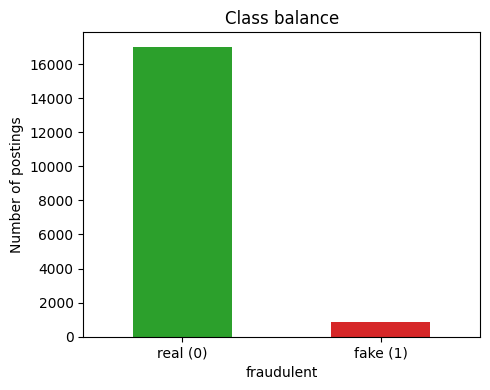

In [5]:
plt.figure(figsize=(5, 4))
df["fraudulent"].value_counts().sort_index().plot.bar(color=["tab:green", "tab:red"])
plt.xticks([0, 1], ["real (0)", "fake (1)"], rotation=0)
plt.title("Class balance")
plt.ylabel("Number of postings")
plt.tight_layout()
plt.savefig("eda_class_balance.png", dpi=150)
plt.show()

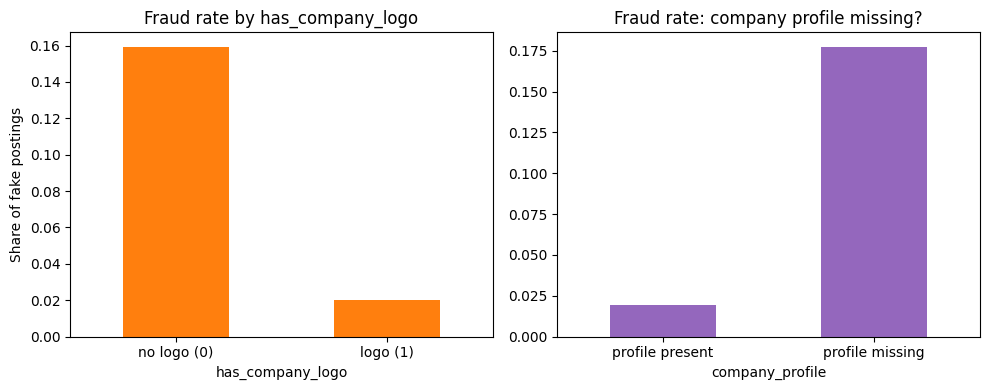

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

df.groupby("has_company_logo")["fraudulent"].mean().plot.bar(ax=ax[0], color="tab:orange")
ax[0].set_title("Fraud rate by has_company_logo")
ax[0].set_ylabel("Share of fake postings")
ax[0].set_xticklabels(["no logo (0)", "logo (1)"], rotation=0)

df.groupby(df["company_profile"].isna())["fraudulent"].mean().plot.bar(ax=ax[1], color="tab:purple")
ax[1].set_title("Fraud rate: company profile missing?")
ax[1].set_xticklabels(["profile present", "profile missing"], rotation=0)

plt.tight_layout()
plt.savefig("eda_fraud_rates.png", dpi=150)
plt.show()

In [7]:
print("Accuracy of always predicting 'real':", round(1 - df["fraudulent"].mean(), 3))

Accuracy of always predicting 'real': 0.952
